# Assignment 2
Due Sep. 16

Yazdan Zinati 
260928077   

Dataset A (classification): for the first set of 5 small programming tasks use the Oasis dataset provided by the nilearn package, which can be downloaded using the code below. This is a dataset of structural brain scans (aka voxel-based morphometry) for male and
female individuals.

In [42]:
from nilearn import datasets
import numpy as np
from nilearn.input_data import NiftiLabelsMasker
brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
yeo = datasets.fetch_atlas_yeo_2011()
masker = NiftiLabelsMasker(labels_img=yeo['thick_17'],
standardize=True, memory='nilearn_cache')
input_variables = masker.fit_transform(brain_data.gray_matter_maps)
output_variable = np.array(brain_data.ext_vars.mf == 'F',
dtype=int) #gives 1 for females and 0 for males

Note: it is expected that the models may not converge with the default max_iter, that is
okay.

1. Use sklearn.linear_model.LogisticRegression(hyperparameter set to
1.0) trained on all 17 input_variables to perform uncertainty estimation. Draw 200
bootstrap samples from the dataset, and for each of these bootstrap datasets, fit
your model on all 100 subjects (you will train 200 models). Plot the distribution of
model parameters(.coef_)using pyplot.boxplot(). The distribution of the model
parameters should be on the y-axis and 17 input variables on the x axis; the mean of
each box is the original point estimate of the model coefficient (i.e., the original
dataset, not the bootstrap data).

In [43]:
print("input variable shape", input_variables.shape)
print("output variable shape", output_variable.shape)

input variable shape (100, 17)
output variable shape (100,)


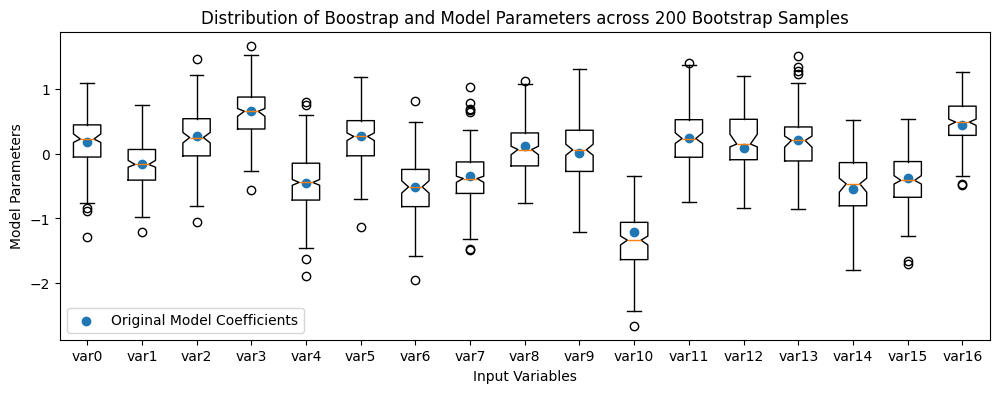

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample
import matplotlib.pyplot as plt

# first we train the logistic regressor (to then do uncertainty estimation on it)
og_regressor = LogisticRegression(C=1.0)
og_regressor.fit(input_variables, output_variable)

og_coefs = og_regressor.coef_.flatten()

boostrap_coefs = []

for i in range(200):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(
        input_variables, output_variable
    )

    # run regressor
    boostrap_regressor = LogisticRegression(C=1.0)
    boostrap_regressor.fit(input_vars_bootstrap, output_vars_bootstrap)
    boostrap_coefs.append(boostrap_regressor.coef_.flatten())

plt.figure(figsize=(12, 4))  # make it longer as to fit all xlabels

plt.scatter(range(1, 18), np.array(og_coefs), label="Original Model Coefficients")
# plt.boxplot(np.array(boostrap_coefs), notch=True, bootstrap=200, conf_intervals=list(og_coefs))

plt.boxplot(np.array(boostrap_coefs), notch=True, bootstrap=200)

# Customize the plot
plt.title("Distribution of Boostrap and Model Parameters across 200 Bootstrap Samples")
plt.xlabel("Input Variables")
plt.ylabel("Model Parameters")
plt.xticks(ticks=np.arange(1, 18), labels=[f"var{i}" for i in range(17)])
plt.legend()
plt.show()

2. Without predictive modeling; using 200 bootstrap iterations, in each drawn
bootstrap dataset, subtract the mean volume in an input variable across males
from the mean volume across females, for each input variable. Then, plot the 5%
and 95% percentiles of the distribution of 200 bootstrapped differences for the
purpose of hypothesis testing (dispersion on the y-axis and input variables on the x-
axis). Hint: use np.percentile().

In [45]:
diff_sex_means = []

for i in range(200):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(
        input_variables, output_variable
    )
    house, face = input_vars_bootstrap[
        output_vars_bootstrap == 0
    ].mean(axis=0), input_vars_bootstrap[output_vars_bootstrap == 1].mean(axis=0)

    diff_sex_means.append(face - house)

diff_sex_means = np.array(diff_sex_means)
percentile5 = np.percentile(diff_sex_means, q=5, axis=0)
percentile95 = np.percentile(diff_sex_means, q=95, axis=0)

/tmp/ipykernel_338804/2049636280.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


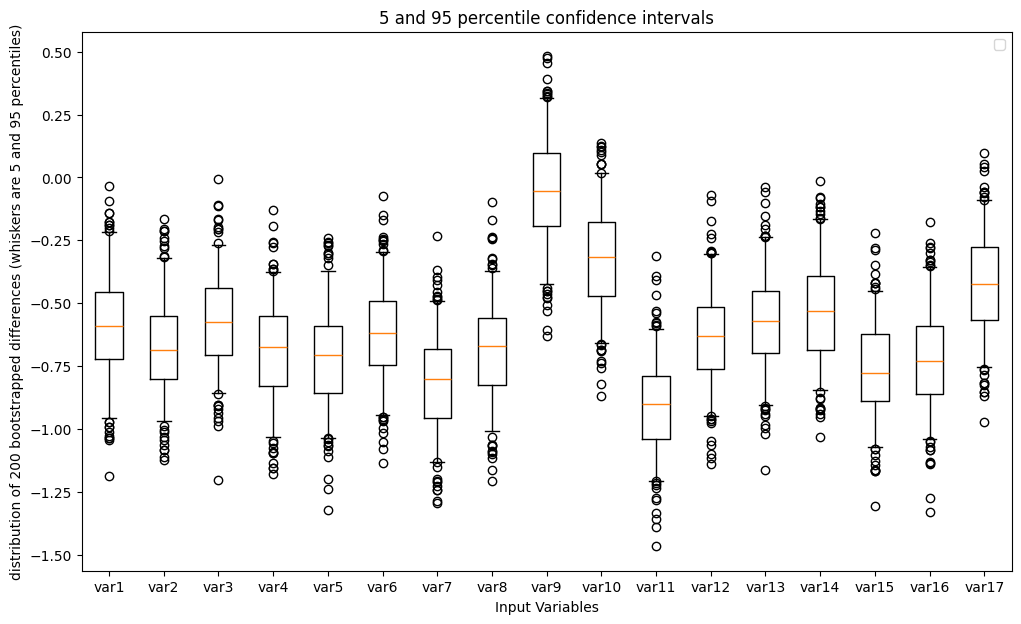

In [46]:
plt.figure(figsize=(12, 7))  # make it longer as to fit all xlabels

# plt.boxplot(np.array(boostrap_coefs), notch=True, bootstrap=200, conf_intervals=list(og_coefs))

plt.boxplot(np.array(diff_sex_means), whis=[5, 95])

# Customize the plot
plt.title("5 and 95 percentile confidence intervals")
plt.xlabel("Input Variables")
plt.ylabel(
    "distribution of 200 bootstrapped differences (whiskers are 5 and 95 percentiles)"
)
plt.xticks(ticks=np.arange(1, 18), labels=[f"var{i}" for i in range(1, 18)])
plt.legend()
plt.show()

Below is a more simplified view of the 5 and 95 percentile plots that only shows those extremities. 

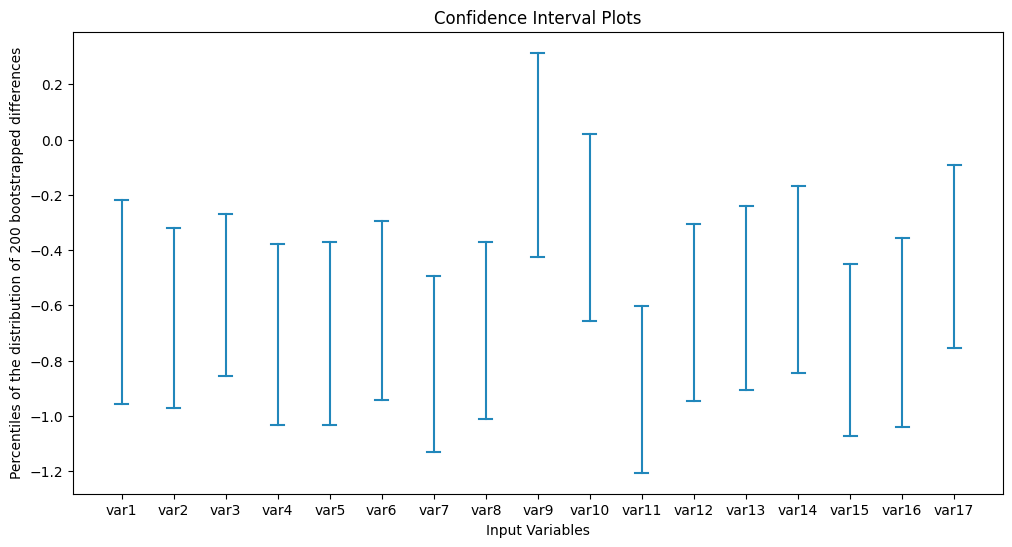

In [47]:
import matplotlib.pyplot as plt


# adapted from https://stackoverflow.com/a/70949996
def plot_confidence_interval(
    x, perc5, perc95, color="#2187bb", horizontal_line_width=0.25
):
    left = x - horizontal_line_width / 2
    top = perc95
    right = x + horizontal_line_width / 2
    bottom = perc5
    plt.plot([x, x], [top, bottom], color=color)
    plt.plot([left, right], [top, top], color=color)
    plt.plot([left, right], [bottom, bottom], color=color)
    # plt.plot(x, mean, 'o', color='#f44336')


plt.figure(figsize=(12, 6))  # make it longer as to fit all xlabels

plt.xticks(list(range(17)), [f"var{i}" for i in range(1, 18)])
plt.title("Confidence Interval Plots")
for i in range(17):
    plot_confidence_interval(i, percentile5[i], percentile95[i])

plt.xlabel("Input Variables")
plt.ylabel("Percentiles of the distribution of 200 bootstrapped differences")
plt.show()

3. Define the training dataset as the first 80 of the 100 subjects, then draw 200
bootstrap samples of this training dataset. On each of the 200 bootstrap samples,
train a logistic regression model
sklearn.linear_model.LogisticRegression(hyperparameter set to 1.0)
to distinguish male versus female participants. Then, building on those 200 fitted
models, improve the prediction performance on the remaining subjects as testingdata (unseen 20% of the 100 subjects) by majority vote (i.e., select the most
common class) across the 200 bootstrapped logistic regression models. Report this
average classification performance (% number, no plot).

In [63]:
from sklearn.metrics import accuracy_score
from scipy import stats

train_inputs, test_inputs, train_output, test_output = (
    input_variables[:80, :],
    input_variables[80:, :],
    output_variable[:80],
    output_variable[80:],
)

assert (
    train_output.shape[0] == train_inputs.shape[0] == 80
    and test_output.shape[0] == test_inputs.shape[0] == 20
)


# calculate accuracy score of a single regressor (no baggin)
boostrap_regressor = LogisticRegression(C=1.0)
boostrap_regressor.fit(train_inputs, train_output)
print("base accuracy score (only 1 regressor):",accuracy_score(test_output, boostrap_regressor.predict(test_inputs)))


regressors = []
preds = []
for i in range(200):
    # create bootstrap sample from the training set 
    input_vars_bootstrap, output_vars_bootstrap = resample(
        train_inputs, train_output
    )

    boostrap_regressor = LogisticRegression(C=1.0)
    boostrap_regressor.fit(input_vars_bootstrap, output_vars_bootstrap)
    preds.append(boostrap_regressor.predict(test_inputs))
    regressors.append(boostrap_regressor)
preds = np.array(preds)
mode_pred = stats.mode(preds, axis=0)
print("classification performance (with bootstrap):",accuracy_score(test_output, mode_pred[0]))


base accuracy score (only 1 regressor): 0.75
classification performance (with bootstrap): 0.8


Note that the "base accuracy score"(1st score) above is the result of predicting sex using a single regressor trained on the training set. We would need to report the average of performance across multiple times to get a performance that is less dependent on randomness. Nonetheless, we do see an improvement with bootstrappig. 

Let's verify our implementation with the sklearn one (gives the same number, good!):

In [62]:
from sklearn.ensemble import BaggingClassifier

bc = BaggingClassifier(estimator = LogisticRegression(), n_estimators = 200).fit(train_inputs, train_output)
print("sklearn implementation of baggin classifier:", accuracy_score(test_output, bc.predict(test_inputs)))

sklearn implementation of baggin classifier: 0.8


4. Define the training dataset as the same 80% of the 100 subjects as in Q3, draw
200 bootstrap samples from this dataset, then train a logistic regression model
sklearn.linear_model.LogisticRegression (hyperparameter set to 1.0)
to distinguish male versus female participants. Average (np.mean) the 200 different
sets of model parameters (.coef_) across the 200 fitted models to better identify the
model parameters and plot them as bar plot (x-axis is the 17 input variable, y axis is
the single mean-averaged parameter value across the bootstrap iterations). Use
these averaged model parameters (coefficients) and the remaining 20% of the 100
subjects as test data in a single logistic regression model to predict male versus
female participants using this new predictive model. Report the classification
performance averaged across the 20 test subjects (% number, no plot).

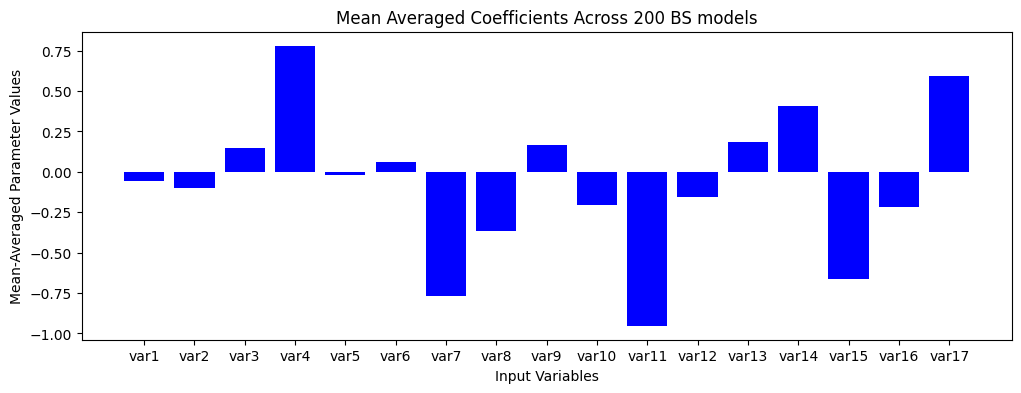

In [68]:
coefs = [regressor.coef_ for regressor in regressors]
coefs = np.array(coefs).mean(axis=1)
means = np.mean(coefs, axis=0).flatten()


plt.figure(figsize=(12, 4))
plt.bar(range(1, 18), means, color='blue')
plt.xlabel('Input Variables')
plt.ylabel('Mean-Averaged Parameter Values')
plt.title('Mean Averaged Coefficients Across 200 BS models')
plt.xticks(ticks=np.arange(1, 18), labels=[f'var{i}' for i in range(1, 18)])
plt.show()


In [70]:
intercepts = [regressor.intercept_ for regressor in regressors]
intercepts = np.array(intercepts).mean(axis=1)
mean_intercept = np.mean(intercepts, axis=0).flatten()
classes = regressors[0].classes_

In [78]:
final_model = LogisticRegression(C=1.0)

# Set the coefficients and  other params by hand
# final_model.fit(train_inputs, train_output)
final_model.coef_ = np.array([means])
final_model.intercept_ = np.array(mean_intercept)
final_model.classes_ = classes
pred = final_model.predict(test_inputs)
accuracy = accuracy_score(test_output, pred)

# Report the classification performance
print("Accuracy:", accuracy)

Accuracy: 0.8


5. Draw 200 bootstrap samples from all 100 subjects and fit a logistic regression
model on each bootstrap sample. Then, perform cross-validation (CV) via out-of-
bag (OOB) evaluation on the remaining (roughly ⅓) unseen (unsampled) subjects
in each bootstrap iteration (recall lecture slides: only ~ 2/3 of the original dataset
shows up in the bootstrap samples). Plot a scatterplot of the OOB CV accuracy for
each bootstrap iteration (x-axis is the 200 iterations, y-axis is the OOB accuracy of
the corresponding model).

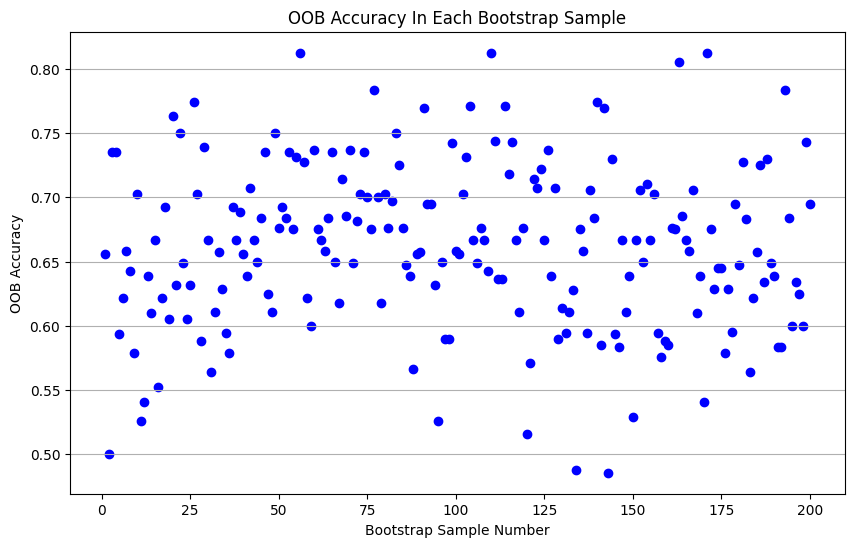

oob mean accuracy: 0.6613985584242619


In [79]:
oob_scores = []
for i in range(200):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(
        input_variables, output_variable, n_samples=100
    )

    # run regressor
    boostrap_regressor = LogisticRegression(C=1.0)
    boostrap_regressor.fit(input_vars_bootstrap, output_vars_bootstrap)


    # find out of bag inputs and outputs
    input_diff_set = set(map(tuple, input_variables)) - set(
        map(tuple, input_vars_bootstrap)
    )

    if len(input_diff_set) == 0:
        print(f"No OOD sample for run {i}/200 of the boostrap")
        continue # only run the rest if there is an oob sample

    input_diff = np.array(list(input_diff_set))

    output_diff_idx = np.array(
        [
            np.where(np.all(input_variables == input_diff[i], axis=1))[0]
            for i in range(input_diff.shape[0])
        ]
    )   

    output_diff = np.array([output_variable[i] for i in output_diff_idx])



    oob_pred = boostrap_regressor.predict(input_diff)
    oob_scores.append(accuracy_score(output_diff, oob_pred))

plt.figure(figsize=(10, 6))
plt.scatter(range(1, len(oob_scores) + 1), oob_scores, color='blue')
plt.xlabel('Bootstrap Sample Number')
plt.ylabel('OOB Accuracy')
plt.title('OOB Accuracy In Each Bootstrap Sample')
plt.grid(axis='y')
plt.show()

print("oob mean accuracy:", np.mean(oob_scores))

Dataset B (regression): for the second set of 5 small programming tasks, use the Haxby
dataset provided by the nilearn package, which can be downloaded using the code below.
This is a dataset of functional brain scans (functional MRI measurements from one subject)
acquired while individuals watched people’s faces or house pictures.

The only relevant horizontal brain slice has 739 voxels.


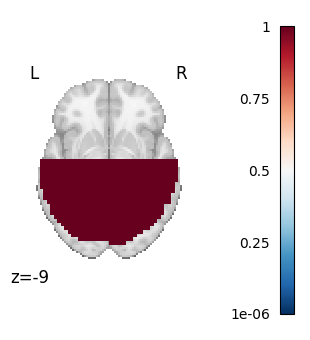

In [80]:
from nilearn import datasets
import numpy as np
import pandas as pd
import nibabel as nib
from nilearn.image import new_img_like
from nilearn.plotting import plot_stat_map
from matplotlib import pylab as plt
haxby_dataset = datasets.fetch_haxby(subjects=1)
mask_filename = haxby_dataset.mask
mask_img = nib.load(mask_filename)
process_mask = mask_img.get_fdata()
picked_slice = 29
process_mask[..., (picked_slice + 1):] = 0
process_mask[..., :picked_slice] = 0
process_mask[:, 30:] = 0 # zero out anterior “half” of the brain
process_mask_img = new_img_like(mask_img, process_mask)
from nilearn.input_data import NiftiMasker
nifti_masker = NiftiMasker(smoothing_fwhm=8,
mask_img=process_mask_img)
func_filename = haxby_dataset.func[0]
fmri_masked = nifti_masker.fit_transform(func_filename)
labels = pd.read_csv(haxby_dataset.session_target[0], sep=" ")
conditions = labels['labels']
condition_mask = conditions.isin(['face', 'house'])
fmri_masked = fmri_masked[condition_mask]
output_variable = np.array(conditions[condition_mask] == 'face',
dtype=int)
print('The only relevant horizontal brain slice has %i voxels.' %
process_mask[..., picked_slice].sum())
#plot that slice to get an impression of where the input variables
# are in the brain 
plot_stat_map(process_mask_img, cut_coords=[-9], display_mode="z", cmap=plt.cm.RdBu_r)

Note: since there are many more input variables in this dataset, for all of the following
questions only generate plots of the first 17 input variables (your models should still be
trained using all input variables). For Q8 and Q9 use an 80/20% train/test split.

In [81]:
# fmri_masked = fmri_masked[:,:17]
fmri_masked.shape

(216, 739)

In [82]:
output_variable.shape

(216,)

6. analogous to task 1 but using sklearn.linear_model.Ridge(default hyperparameters)
instead of logistic regression.

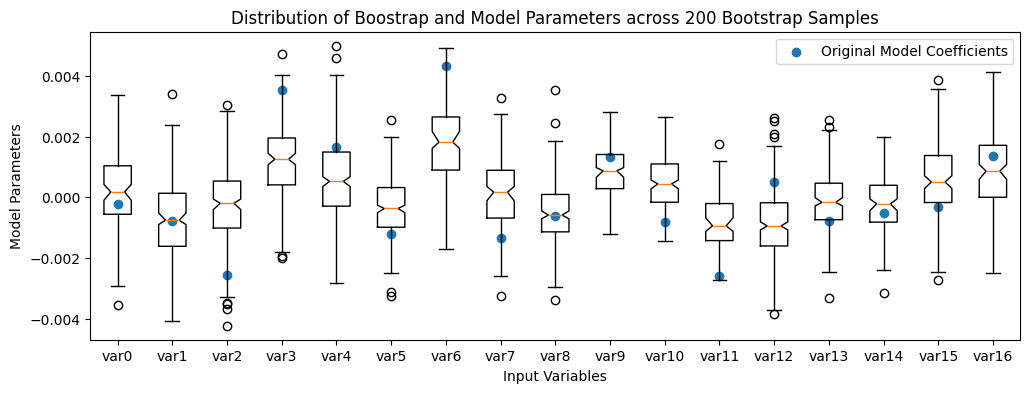

In [93]:
from sklearn.linear_model import Ridge

# first we train the logistic regressor (to then do uncertainty estimation on it)
og_regressor = Ridge()
og_regressor.fit(fmri_masked, output_variable)

og_coefs = og_regressor.coef_.flatten()[:17]

boostrap_coefs = []

for i in range(200):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(fmri_masked, output_variable)
    # run regressor
    boostrap_regressor = Ridge()
    boostrap_regressor.fit(input_vars_bootstrap, output_vars_bootstrap)
    boostrap_coefs.append(boostrap_regressor.coef_.flatten()[:17])
    
plt.figure(figsize=(12, 4))  # make it longer as to fit all xlabels

plt.scatter(range(1, 18), np.array(og_coefs), label="Original Model Coefficients")
# plt.boxplot(np.array(boostrap_coefs), notch=True, bootstrap=200, conf_intervals=list(og_coefs))


plt.boxplot(np.array(boostrap_coefs), notch=True, bootstrap=200)

# Customize the plot
plt.title("Distribution of Boostrap and Model Parameters across 200 Bootstrap Samples")
plt.xlabel("Input Variables")
plt.ylabel("Model Parameters")
plt.xticks(ticks=np.arange(1, 18), labels=[f"var{i}" for i in range(17)])
plt.legend()
plt.show()

7. analogous to task 2

In [94]:
# face = 1, house = 0 

diff_conditions_means = []

for i in range(200):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(
        fmri_masked, output_variable
    )
    house, face = input_vars_bootstrap[
        output_vars_bootstrap == 0
    ].mean(axis=0), input_vars_bootstrap[output_vars_bootstrap == 1].mean(axis=0)

    diff_conditions_means.append(face - house)

diff_conditions_means = np.array(diff_conditions_means)[:, :17]
percentile5 = np.percentile(diff_conditions_means, q=5, axis=0)
percentile95 = np.percentile(diff_conditions_means, q=95, axis=0)

/tmp/ipykernel_338804/2338255189.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


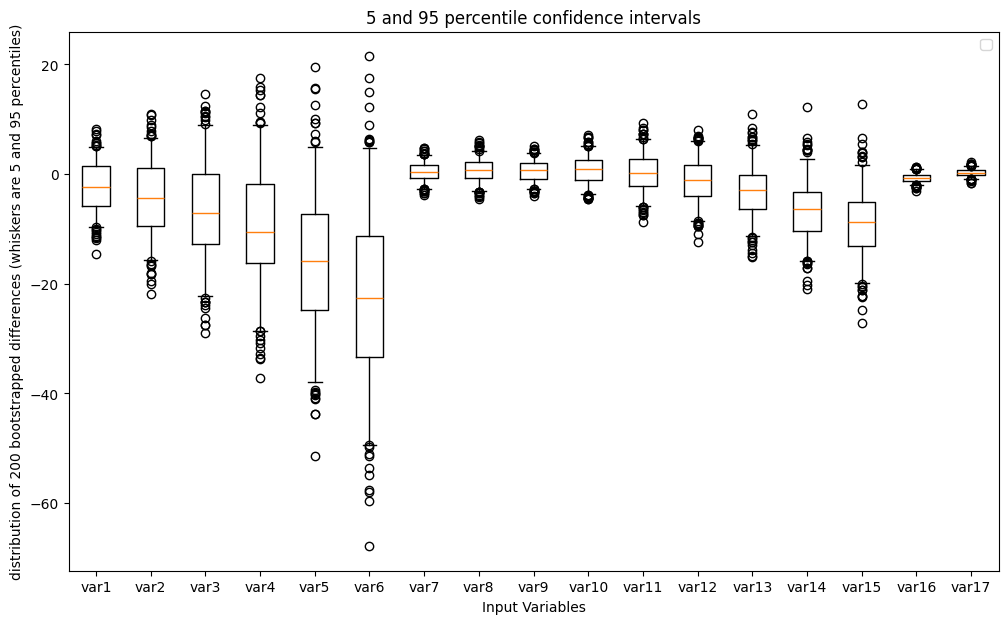

In [95]:
plt.figure(figsize=(12, 7))  # make it longer as to fit all xlabels

# plt.boxplot(np.array(boostrap_coefs), notch=True, bootstrap=200, conf_intervals=list(og_coefs))

plt.boxplot(np.array(diff_conditions_means), whis=[5, 95])

# Customize the plot
plt.title("5 and 95 percentile confidence intervals")
plt.xlabel("Input Variables")
plt.ylabel(
    "distribution of 200 bootstrapped differences (whiskers are 5 and 95 percentiles)"
)
plt.xticks(ticks=np.arange(1, 18), labels=[f"var{i}" for i in range(1, 18)])
plt.legend()
plt.show()

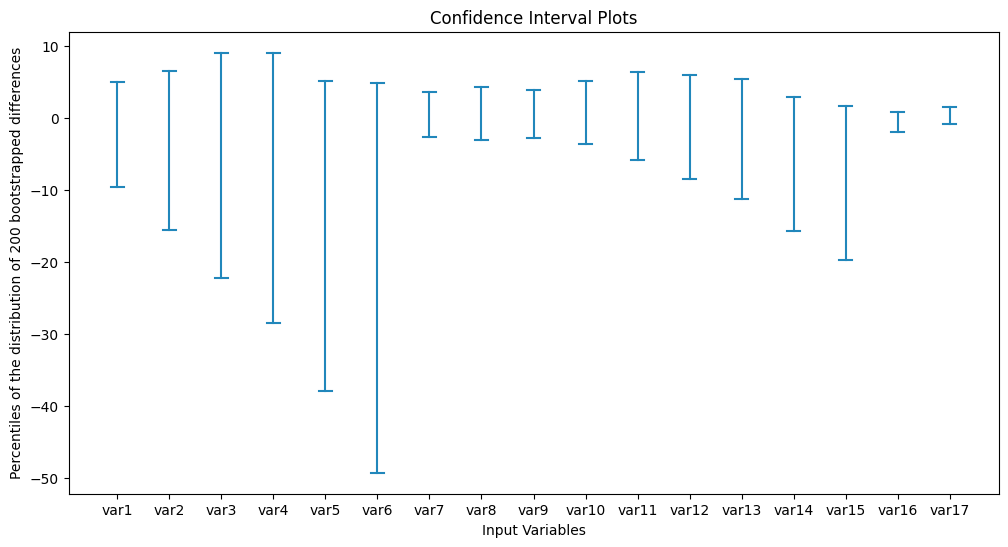

In [96]:
import matplotlib.pyplot as plt


# adapted from https://stackoverflow.com/a/70949996
def plot_confidence_interval(
    x, perc5, perc95, color="#2187bb", horizontal_line_width=0.25
):
    left = x - horizontal_line_width / 2
    top = perc95
    right = x + horizontal_line_width / 2
    bottom = perc5
    plt.plot([x, x], [top, bottom], color=color)
    plt.plot([left, right], [top, top], color=color)
    plt.plot([left, right], [bottom, bottom], color=color)
    # plt.plot(x, mean, 'o', color='#f44336')


plt.figure(figsize=(12, 6))  # make it longer as to fit all xlabels

plt.xticks(list(range(17)), [f"var{i}" for i in range(1, 18)])
plt.title("Confidence Interval Plots")
for i in range(17):
    plot_confidence_interval(i, percentile5[i], percentile95[i])

plt.xlabel("Input Variables")
plt.ylabel("Percentiles of the distribution of 200 bootstrapped differences")
plt.show()

8. analogous to task 3 but using sklearn.linear_model.Ridge(default hyperparameters).
Instead of predicting the binary class and using majority vote to calculate
classification accuracy, use the average of the 200 bootstrap predictions to score
(Ridge.score()) the performance on the test subjects.

In [100]:
from sklearn.metrics import r2_score
import warnings
import scipy

warnings.filterwarnings(action='ignore', category=scipy.linalg.LinAlgWarning)

train_set_size = int(fmri_masked.shape[0] * 0.8)
test_set_sie = fmri_masked.shape[0] - train_set_size

train_inputs, test_inputs, train_output, test_output = (
    fmri_masked[:train_set_size, :],
    fmri_masked[train_set_size:, :],
    output_variable[:train_set_size],
    output_variable[train_set_size:],
)

assert (
    train_output.shape[0] == train_inputs.shape[0] == train_set_size
    and test_output.shape[0] == test_inputs.shape[0] == test_set_sie
)

# calculate accuracy score of a single regressor (no baggin)
boostrap_regressor = Ridge()
boostrap_regressor.fit(train_inputs, train_output)
pred = boostrap_regressor.predict(test_inputs)
print("base regression score (only 1 regressor):", r2_score(test_output, pred))


regressors = []
preds = []
for i in range(200):
    # create bootstrap sample from the training set 
    input_vars_bootstrap, output_vars_bootstrap = resample(
        train_inputs, train_output
    )

    boostrap_regressor = Ridge()
    boostrap_regressor.fit(input_vars_bootstrap, output_vars_bootstrap)
    preds.append(boostrap_regressor.predict(test_inputs))
    regressors.append(boostrap_regressor)

preds = np.array(preds)
mean_preds = np.mean(preds, axis=0)
print("regression score (baggin):", r2_score(test_output, mean_preds))


base regression score (only 1 regressor): 0.39378446340560913
regression score (baggin): 0.6354931592941284


let's verify with the sklearn implementation

In [103]:
from sklearn.ensemble import BaggingRegressor

bc = BaggingRegressor(estimator = Ridge(), n_estimators = 200).fit(train_inputs, train_output)
print("sklearn implementation of baggin classifier:", bc.score(test_inputs, test_output))

sklearn implementation of baggin classifier: 0.6045790910720825


9. analogous to task 4 but using sklearn.linear_model.Ridge(default hyperparameters)
and using the coefficient of determination instead of accuracy

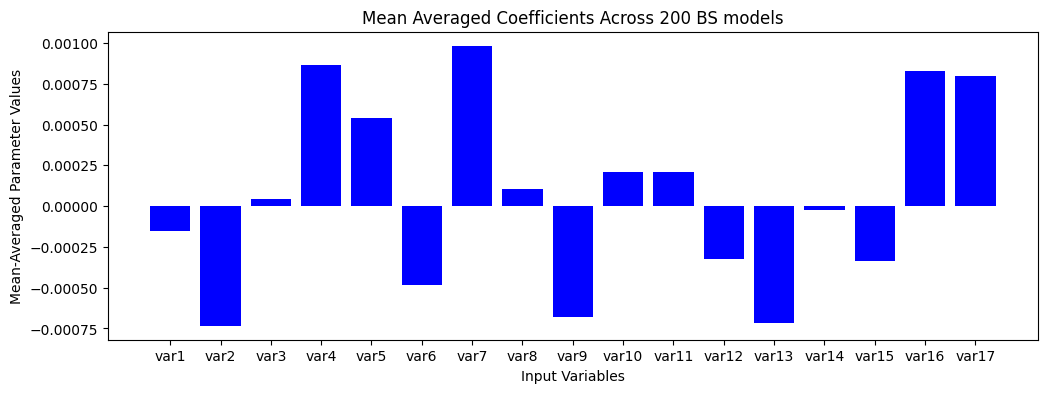

In [104]:
coefs = [regressor.coef_ for regressor in regressors]
coefs = np.array(coefs)
means = np.mean(coefs, axis=0).flatten()
means_plot = means[:17]
intercepts = np.array([regressor.intercept_ for regressor in regressors])
intercepts_mean = intercepts.mean()

plt.figure(figsize=(12, 4))
plt.bar(range(1, 18), means_plot, color='blue')
plt.xlabel('Input Variables')
plt.ylabel('Mean-Averaged Parameter Values')
plt.title('Mean Averaged Coefficients Across 200 BS models')
plt.xticks(ticks=np.arange(1, 18), labels=[f'var{i}' for i in range(1, 18)])
plt.show()


In [105]:
final_model = Ridge()

# Set the coefficients and  other params by hand
# final_model.fit(train_inputs, train_output)
final_model.coef_ = np.array([means])
final_model.intercept_ = intercepts_mean

pred = final_model.predict(test_inputs)
score = r2_score(test_output, pred)

# Report the classification performance
print("coefficient of determination:", score)

coefficient of determination: 0.6354892253875732


10. analogous to task 5 but using sklearn.linear_model.Ridge(default hyperparameters)
and using the coefficient of determination instead of accuracy

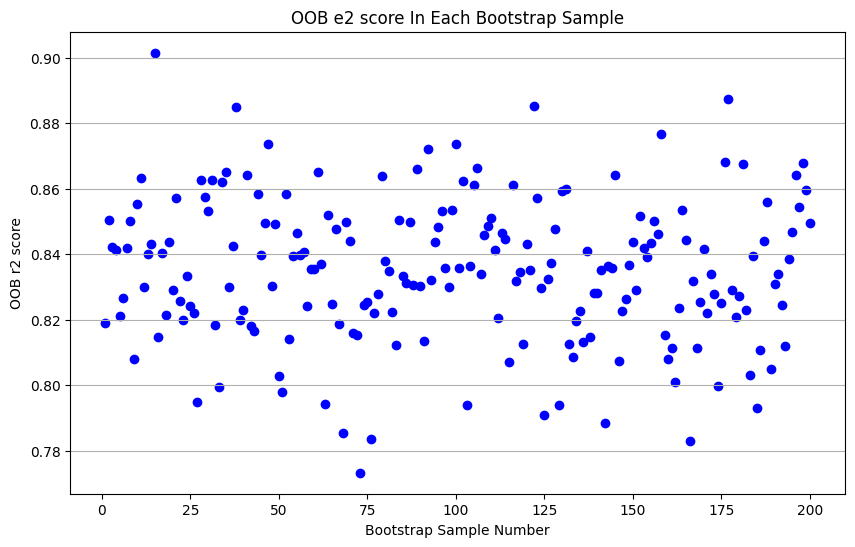

oob mean score: 0.8349669590592385


In [112]:
oob_scores = []
for i in range(200):
    # create bootstrap sample
    input_vars_bootstrap, output_vars_bootstrap = resample(
        fmri_masked, output_variable
    )

    # run regressor
    boostrap_regressor = Ridge()
    boostrap_regressor.fit(input_vars_bootstrap, output_vars_bootstrap)


    # find out of bag inputs and outputs
    input_diff_set = set(map(tuple, fmri_masked)) - set(
        map(tuple, input_vars_bootstrap)
    )

    if len(input_diff_set) == 0:
        print(f"No OOD sample for run {i}/200 of the boostrap")
        continue # only run the rest if there is an oob sample

    input_diff = np.array(list(input_diff_set))

    output_diff_idx = np.array(
        [
            np.where(np.all(fmri_masked == input_diff[i], axis=1))[0]
            for i in range(input_diff.shape[0])
        ]
    )   

    output_diff = np.array([output_variable[i] for i in output_diff_idx])

    assert output_diff.shape[0] + len(set(map(tuple,input_vars_bootstrap))) == fmri_masked.shape[0]

    # oob_scores.append(boostrap_regressor.score(input_diff, output_diff))
    oob_scores.append(r2_score(output_diff, boostrap_regressor.predict(input_diff)))
plt.figure(figsize=(10, 6))
plt.scatter(range(1, len(oob_scores) + 1), oob_scores, color='blue')
plt.xlabel('Bootstrap Sample Number')
plt.ylabel('OOB r2 score')
plt.title('OOB e2 score In Each Bootstrap Sample')
plt.grid(axis='y')
plt.show()

print("oob mean score:", np.mean(oob_scores))